# Configuración del Entorno y Librerías

### Inicialización del Backend, Semillas y Dependencias:

Esta sección se configura el entorno de ejecución  de **Keras** utilizando **PyTorch** como motor (*backend*), se cargan todas las librerías matemáticas, de visualización, procesamiento de imágenes y métricas de evaluación necesarias para el desarrollo del proyecto.

#### Componentes Clave:

| Componente / Librería | ¿Qué hace en la práctica? |
| :--- | :--- |
| ⚙  **Keras + PyTorch** (`os.environ`) | Configura a Keras para que utilice **PyTorch** como **backend** para hacer todos los cálculos pesados de las matrices. |
| 📐 **Keras** (`layers`, `models`, `regularizers`) | Se importan las librerías necesarias para armar la arquitectura de la red neuronal |
| 🧠 **Optimizadores y Callbacks** (`Adam`, `EarlyStopping`, `ReduceLROnPlateau`) | Controlan la velocidad de aprendizaje de la red, __Adam__ como optimizador, ReduceLROnPlateu para modificar el __Learning Rate__ en una meseta y __EarlyStopping__ para detener el entrenamiento si no hay mejora. |
| 🔢 **NumPy y Scikit-Learn** (`numpy`, `train_test_split`) | Librerías para cálculos matemáticos y estadísticos, con el fin de procesar las matrices de datos. |
| 🖼 **OpenCV** (`cv2`) | Librería para leer y manipular imágenes, se usa para procesar el gradiente (Sobel) y generar un 4° canal de información en el modelo B. |
| 📊 **Visualización** (`matplotlib`, `seaborn`, `MaxNLocator`) | Las librerías para generar gráficas, útiles para graficar la trazabilidad del entrenamiento y el desempeño final (hearmap).|
| 🌱 **Semillas** (`SEED = 42`,`SEED_2 = 30`) | Fija un punto de partida aleatorio fijo para todo el notebook, para que las funciones que dependen de la aleatoriedad puedan ser reproducibles y comprobables.|

In [2]:
import os
os.environ["KERAS_BACKEND"] = "torch"   #<- Set Pytorch as engine Keras backend 
import keras 
from keras import layers, models, regularizers
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split
import cv2 as openCV
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

# Use just one of this  
SEED =42
SEED_2 = 30
try: 
    keras.utils.set_random_seed(SEED_2) # <-Set Random seed to fixed value to grant reproducibility

    print("Backend configurado con éxito:", keras.backend.backend())
    print("Versión de Keras:", keras.__version__)
except Exception as Error:
    print (f"Error al configurar el Backend de Keras: {Error}")


Backend configurado con éxito: torch
Versión de Keras: 3.15.1


# Carga y exploración del Dataset 
Esta celda se encarga de la preparación de los datos.
#### Paso 1 - Descarga:
Se descarga **CIFAR-100** directamente desde las librerías de Keras,  con las imágenes (RGB) y sus 100 clases detalladas. 
#### Paso 2 - Normalización: 
Se normalizan los pixeles dividiéndolos entre 255 (rango máximo de luminosidad), pasando los valores de un rango de 0-255 a decimales limpios entre 0.0 y 1.0, para que el modelo  converja mucho más rápido.
#### Paso 3 - División:
Se toma el macro conjunto de entrenamiento y se divide usando la función `train_test_split`. Se aparta un 15% de esos datos para usarlos como **validación** durante el proceso de entrenamiento antes de probar el modelo con el conjunto de prueba. 
**Nota**: Se usa el parámetro (`stratify`) para asegurar que el reparto de las 100 clases sea equitativo tanto en el conjunto de entrenamiento como en el de validación, es decir, mantener la proporción en ambos conjuntos durante el entrenamiento. 

In [3]:
try:
    # Load CIFAR-100 in "fine" mode (100 classes, RGB inputs)
    (x_train_full, y_train_full), (x_test, y_test) = keras.datasets.cifar100.load_data(label_mode="fine")

    print(f"Dimensiones del macro-conjunto de entrenamiento. Tensor X: {x_train_full.shape}, Tensor Y: {y_train_full.shape}.")
    print(f"Dimensiones del macro-conjunto de prueba. Tensor X: {x_test.shape}, Tensor Y: {y_test.shape}.")

    # Normalization of both sets (training and test) just for the input Tensors, Output tensors are integers from 0 to 99 
    x_train_full = x_train_full.astype("float32") / 255.0       # Input tensors range are 0 to 255, normalize from 0 to 1
    x_test = x_test.astype("float32") / 255.0

    # Split train sets (X and Y tensors) in train and validation subsets
    x_train, x_val, y_train, y_val = train_test_split(
        x_train_full, 
        y_train_full, 
        test_size=0.15,         # <-15% data for validation porpuses (Inside train macro Set)
        random_state=SEED_2,        
        stratify=y_train_full   # <-Use stratify to keep the same proportion of classes in X and Y sets
    )

    print("-" * 50)
    print("Partición para el conjunto de entrenamiento, validación y prueba")
    print("Entrenamiento:", x_train.shape, y_train.shape)
    print("Validación:   ", x_val.shape, y_val.shape)
    print("Prueba (Test): ", x_test.shape, y_test.shape)

except Exception as Error:
    print (f"Error durante la carga y normalización de los datos: {Error}")


C:\Users\Abrah\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\datasets\cifar.py:18: VisibleDeprecationWarning: dtype(): align should be passed as Python or NumPy boolean but got `align=0`. Did you mean to pass a tuple to create a subarray type? (Deprecated NumPy 2.4)
  d = RestrictedUnpickler(f, encoding="bytes").load()


Dimensiones del macro-conjunto de entrenamiento. Tensor X: (50000, 32, 32, 3), Tensor Y: (50000, 1).
Dimensiones del macro-conjunto de prueba. Tensor X: (10000, 32, 32, 3), Tensor Y: (10000, 1).
--------------------------------------------------
Partición para el conjunto de entrenamiento, validación y prueba
Entrenamiento: (42500, 32, 32, 3) (42500, 1)
Validación:    (7500, 32, 32, 3) (7500, 1)
Prueba (Test):  (10000, 32, 32, 3) (10000, 1)


# Construcción del rasgo diseñado
Esta celda se encarga de procesar las imágenes para extraer los bordes y contornos utilizando el filtro de Sobel, creando así un canal adicional de información para alimentar el Modelo B.
### Paso 1 - Conversión a Escala de Grises:
Cada imagen a color (RGB) se convierte a escala de grises utilizando OpenCV, de esta forma, la detección de contornos es más eficiente al detectar sólo cambios de luminosidad.
### Paso 2 - Aplicación del Filtro Sobel y Magnitud:
Se calculan los gradientes espaciales en los ejes X e Y usando un kernel de $3 \times 3$. A partir de ambos componentes, se obtiene la **magnitud del gradiente** aplicando el teorema de Pitágoras ($\sqrt{sobel\_x^2 + sobel\_y^2}$), lo que resalta los bordes de los objetos. La magnitud resultante se normaliza a un rango de 0.0 a 1.0.
### Paso 3 - Concatenación de Canales (Modelo B):
Se agrega el canal de gradiente (Sobel) como una dimensión extra a las imágenes originales, transformando las matrices de entrada de 3 canales (RGB) a **4 canales (RGB + Sobel)** tanto para el conjunto de entrenamiento como para el de prueba (`np.concatenate`).
### Paso 4 - División Estratificada:
Siguiendo la misma lógica del Modelo A, el macroconjunto de entrenamiento del Modelo B se divide utilizando `train_test_split`, separando un 15% para **validación** y utilizando el parámetro `stratify` para garantizar que la proporción de las 100 clases se mantenga exactamente igual en ambos subconjuntos. Al final, se imprimen las dimensiones de los tensores para confirmar que el Modelo B cuenta con una dimensión extra.

In [4]:
def Extract_Sobel(images):
    sobel_channels = []     #<- Creates a list for sobel channels (gradient) in matrix format
    KERNEL =3
    for img in images:        
        gray = openCV.cvtColor(img, openCV.COLOR_RGB2GRAY)  # <- Converts original images in grayscale using OpenCV
        
        # Apply sobel filter to X and Y dimentions of the immage using 3x3 kernel
        sobel_x = openCV.Sobel(gray, openCV.CV_32F, 1, 0, ksize=KERNEL)
        sobel_y = openCV.Sobel(gray, openCV.CV_32F, 0, 1, ksize=KERNEL)
        magnitude = np.sqrt(sobel_x**2 + sobel_y**2)    # <- Get MAGNITUDE OF GRADIENT using X and Y components and pitagoras theorem
        
        if magnitude.max() > 0:
            magnitude = magnitude / magnitude.max() # Normalize magnitude to range (0-1)

        sobel_channels.append(magnitude)
        # This function returns a an array of n (gradients),1 (new dimension) 
    return np.array(sobel_channels, dtype="float32")[..., np.newaxis]

# Calculate gradients via sobel filter for both macrosets train and test
print("Calculando canales Sobel para el conjunto de entrenamiento completo...")
sobel_train_full = Extract_Sobel(x_train_full)
print("Calculando canales Sobel para el conjunto de prueba...")
sobel_test = Extract_Sobel(x_test)

# Concatenate gradients matrix to both macro sets (Test and Train) to create B Macrosets
x_train_full_b = np.concatenate([x_train_full, sobel_train_full], axis=-1)
x_test_b = np.concatenate([x_test, sobel_test], axis=-1)

# Apply stratified division for B model, by split the same proportion of Train macro set
x_train_b, x_val_b, y_train_b, y_val_b = train_test_split(
    x_train_full_b, 
    y_train_full,      # Y tensor does not include gradients, cause its just integers from 0 to 100 (classes)
    test_size=0.15, 
    random_state=SEED_2, 
    stratify=y_train_full
)

print("-" * 50)
print("Dimensiones del Modelo A (RGB):      ", x_train.shape)
print("Dimensiones del Modelo B (RGB+Sobel):", x_train_b.shape)

Calculando canales Sobel para el conjunto de entrenamiento completo...
Calculando canales Sobel para el conjunto de prueba...
--------------------------------------------------
Dimensiones del Modelo A (RGB):       (42500, 32, 32, 3)
Dimensiones del Modelo B (RGB+Sobel): (42500, 32, 32, 4)


# Definición de la arquitectura de la red Convolucional (CNN)
Esta celda define la función `design_CNN` para construir la arquitectura de la red neuronal, aplicarla tanto al Modelo A como al Modelo B, y compilarla con sus respectivas configuraciones de optimización.

#### Bloques Convolucionales:
La red se compone de 3 bloques progresivos de extracción de características:
* **Bloque 1 y 2:** Utilizan capas de doble convolución (`Conv2D` con 32 y 64 filtros respectivamente y padding 'same') usando activación ReLU para capturar patrones espaciales, seguidas de normalización (`BatchNormalization`), reducción espacial con `MaxPooling2D` a la mitad de su tamaño, y capas de `Dropout` para evitar el sobreajuste.
* **Bloque 3:** Un bloque más profundo con 128 filtros, reducción espacial y una tasa de *Dropout* ajustada.
#### Capas Densas y Clasificación:
* **Aplanado (`Flatten`):** Convierte el mapa tridimensional de características de la última capa convolucional en un vector unidimensional plano.
* **Capa Densa Oculta:** Contiene 256 neuronas con activación ReLU y regularización L2 (`kernel_regularizer=regularizers.l2(0.001)`), complementada con normalización y un *Dropout* del 40% (`0.4`) para mitigar fuertemente el sobreajuste.
* **Capa de Salida:** Una capa densa final con 100 neuronas y activación `softmax`, encargada de arrojar la probabilidad final para cada una de las 100 clases de CIFAR-100.
#### Compilación del Modelo:
Se instancia el optimizador `Adam` con una tasa de aprendizaje inicial de `0.001`, y se compila el modelo utilizando la función de pérdida `sparse_categorical_crossentropy` para clasificaciones multiclase y la métrica de exactitud (`accuracy`).
#### Instanciación y Resumen:
Se generan las dos variantes de la red (`modelo_a` para el formato RGB de 3 canales y `modelo_b` para el formato RGB + Sobel de 4 canales) utilizando las dimensiones correspondientes de sus entradas, imprimiendo el resumen estructural de ambas arquitecturas en consola a través del método `sumary()`.


In [5]:
def design_CNN(input_shape):
    model = models.Sequential([
        # 1st convolution block
        layers.Input(shape=input_shape),    # Indicates to CNN the shape of input data 
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'), # Convolution layer with 32 filters output
        layers.BatchNormalization(),        # Normalization of data
        layers.Conv2D(32, (3, 3), padding='same', activation='relu'), # Convolution layer with 32 filters output
        layers.BatchNormalization(),        # Normalization of data
        layers.MaxPooling2D((2, 2)),        # 0 params, just reduce dimension to half (16x16)
        layers.Dropout(0.2),               # 0 params, just "turn off" 15% of random neurons to avoid overfit over these

        # 2nd convolution block
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'), # Convolution layer with 64 filters output
        layers.BatchNormalization(),        # Normalization of data
        layers.Conv2D(64, (3, 3), padding='same', activation='relu'), # Convolution layer with 64 filters output
        layers.BatchNormalization(),        # Normalization of data
        layers.MaxPooling2D((2, 2)),        # 0 params, just reduce dimension to half (8x8)
        layers.Dropout(0.2),               # 0 params, just "turn off" 15% of random neurons to avoid overfit over these

        # 3rd convolution block
        layers.Conv2D(128, (3, 3), padding='same', activation='relu'), # Convolution layer with 128 filters output
        layers.BatchNormalization(),        # Normalization of data
        layers.MaxPooling2D((2, 2)),        # 0 params, just reduce dimension to half (8x8)
        layers.Dropout(0.25),                # 0 params, just "turn off" 20% of random neurons to avoid overfit over these

    
        layers.Flatten(),                   # 0 params, just vectorize the previous output
        layers.Dense(256, activation='relu', kernel_regularizer=regularizers.l2(0.001)),  # Dense layer with 256 output connections
        layers.BatchNormalization(),        # Normalization of data
        layers.Dropout(0.4),                # 0 params, just "turn off" 25% of random neurons to avoid overfit over these
        layers.Dense(100, activation='softmax')  
    ])    

    custom_optimizer = Adam(learning_rate=0.001)
    model.compile(
        optimizer=custom_optimizer,
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

modelo_a = design_CNN(input_shape=x_train.shape[1:])
print("=== RESUMEN DEL MODELO A (RGB) ===")
modelo_a.summary()
print("\n" + "="*50 + "\n")

modelo_b = design_CNN(input_shape=x_train_b.shape[1:])
print("=== RESUMEN DEL MODELO B (RGB + Sobel) ===")
modelo_b.summary()

=== RESUMEN DEL MODELO A (RGB) ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 691,972 (2.64 MB)

 Trainable params: 690,820 (2.64 MB)

...

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 32)     │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 100)            │        25,700 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 692,260 (2.64 MB)

 Trainable params: 691,108 (2.64 MB)

 Non-trainable params: 1,152 (4.50 KB)

# Entrenamiento del modelo A (Base RGB)
Esta celda define los parámetros de control y ejecuta el entrenamiento del **Modelo A (RGB)** utilizando herramientas de control para evitar el sobreajuste y optimizar el aprendizaje.
### Paso 1 - Definición de Hiperparámetros:
* **Épocas (`EPOCHS = 30`):** Se establece un límite máximo de 30 épocas de entrenamiento sobre todo el conjunto de datos.
* **Tamaño de lote (`BATCH_SIZE = 64`):** Define cuantas imágenes se procesarán por bloques; en este caso, 64 unidades para mantener un uso de memoria estable (alrededor del 80%).
### Paso 2 - Configuración de Callbacks (Control Inteligente):
* **Early Stopping (`EarlyStopping`):** Vigila la exactitud del modelo en el conjunto de validación (`val_accuracy`). Si detecta que pasan 4 épocas (`patience=4`) sin una mejora significativa (`min_delta=0.005`), detiene automáticamente el entrenamiento antes de que ocurra sobreajuste y recupera los mejores pesos obtenidos (`restore_best_weights=True`).
* **Learning Rate Dinámico (`ReduceLROnPlateau`):** Monitorea la pérdida en validación (`val_loss`). Si la red se estanca durante 2 épocas (`patience=2`), reduce a la mitad (`factor=0.5`) la tasa de aprendizaje para dar pasos más precisos, con un límite inferior de seguridad (`min_lr=1e-6`) y avisando por consola cada que se ajusta el *learning rate* (`verbose=1`).

### Paso 3 - Ejecución del Entrenamiento (`.fit`):
Se entrena el `modelo_a` alimentándolo con los datos de entrenamiento (`x_train`, `y_train`) y evaluándolos en cada época con los datos de validación (`x_val`, `y_val`). Todo el historial de exactitud y pérdida queda guardado en la variable `history_a` para su análisis y graficación.

In [6]:
# Training parameters
EPOCHS = 30                 # Maximum epochs to training
BATCH_SIZE = 64             # Maximum batch size of imagges, with this batch memory ussage arrives till 80%

early_stop = EarlyStopping(
    monitor='val_accuracy',
    min_delta=0.005,         # Minimum delta required in accuracy to avoid early stopping 
    patience=4,              # Stop if detect 4 epochs with no improvement
    restore_best_weights=True # Return weights of best epoch
)

lr_scheduler = ReduceLROnPlateau(
    monitor='val_loss',      # Monitor the loss during validation stageMonitorea la pérdida en validación
    factor=0.5,              # Reduce learning rate to half when learning arrives to a plateu 
    patience=2,              # If loss is not improvving after 2 epochs, reduce LR
    min_lr=1e-6,             # Minimum limit for Learning Rate
    verbose=1                # Prints in the output console, every time the learning rate is adjusted
)

print("=== ENTRENANDO MODELO A (RGB) ===")
# Save history of A model in this variable "history_a" to evaluate its results
history_a = modelo_a.fit(               
    x_train, y_train,                    # Traning data to model A
    validation_data=(x_val, y_val),      # Global data validation
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop,lr_scheduler], # Use of early stop and dynamic learning rate
    verbose=1
)
print("\n" + "="*50 + "\n")


=== ENTRENANDO MODELO A (RGB) ===
Epoch 1/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 75s 112ms/step - accuracy: 0.1332 - loss: 4.3179 - val_accuracy: 0.2347 - val_loss: 3.6079 - learning_rate: 0.0010
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 70s 106ms/step - accuracy: 0.2684 - loss: 3.3367 - val_accuracy: 0.3359 - val_loss: 2.9784 - learning_rate: 0.0010
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 71s 106ms/step - accuracy: 0.3432 - loss: 2.9256 - val_accuracy: 0.3065 - val_loss: 3.2048 - learning_rate: 0.0010
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 73s 109ms/step - accuracy: 0.3846 - loss: 2.7373 - val_accuracy: 0.3975 - val_loss: 2.6667 - learning_rate: 0.0010
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 74s 111ms/step - accuracy: 0.4140 - loss: 2.6141 - val_accuracy: 0.4425 - val_loss: 2.5205 - learning_rate: 0.0010
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 76s 114ms/step - accuracy: 0.4314 - loss: 2.5300 - val_accuracy: 0.3803 - val_loss: 2.8374 - learning_rate: 0.0010
Epoch 7/30
665/665 ━━━━━━━━━━━━━━━━━

# Entrenamiento del modelo B (Base RGB + Sobel)
Entrenar el segundo modelo bajo exactamente los mismos hiperparámetros, semilla y épocas que el Modelo A, pero recibiendo el tensor de entrada extendido (4 canales).   

In [7]:

print("=== ENTRENANDO MODELO B (RGB + Sobel) ===")
# Save history of B model in this variable "history_b" to evaluate its results
history_b = modelo_b.fit(
    x_train_b, y_train_b,                # Training data from Model B 
    validation_data=(x_val_b, y_val_b),  # Validation data from Model B 
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stop, lr_scheduler],
    verbose=1
)

=== ENTRENANDO MODELO B (RGB + Sobel) ===
Epoch 1/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 81s 122ms/step - accuracy: 0.1373 - loss: 4.2764 - val_accuracy: 0.1943 - val_loss: 3.7332 - learning_rate: 0.0010
Epoch 2/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 76s 115ms/step - accuracy: 0.2656 - loss: 3.3657 - val_accuracy: 0.3175 - val_loss: 3.0720 - learning_rate: 0.0010
Epoch 3/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 73s 109ms/step - accuracy: 0.3386 - loss: 2.9500 - val_accuracy: 0.3699 - val_loss: 2.8173 - learning_rate: 0.0010
Epoch 4/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 72s 108ms/step - accuracy: 0.3766 - loss: 2.7717 - val_accuracy: 0.4073 - val_loss: 2.6482 - learning_rate: 0.0010
Epoch 5/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 74s 111ms/step - accuracy: 0.4068 - loss: 2.6374 - val_accuracy: 0.4281 - val_loss: 2.5565 - learning_rate: 0.0010
Epoch 6/30
665/665 ━━━━━━━━━━━━━━━━━━━━ 73s 109ms/step - accuracy: 0.4319 - loss: 2.5411 - val_accuracy: 0.4299 - val_loss: 2.5815 - learning_rate: 0.0010
Epoch 7/30
665/665 ━━━━━━━━━

# Comparación de métricas 
Esta celda somete a ambos modelos a la prueba definitivautilizando los conjuntos de prueba aislados (`x_test` y `x_test_b`), los cuales contienen imágenes que los modelos jamás vieron ni durante el entrenamiento ni en la validación.

#### Paso 1 - Evaluación del Modelo A (RGB):
Se utiliza el método `.evaluate()` para calcular la pérdida y la exactitud del `modelo_a` sobre el conjunto de prueba original de 3 canales. El resultado final de la exactitud se multiplica por 100 y se imprime formateado en pantalla con dos decimales.

#### Paso 2 - Evaluación del Modelo B (RGB + Sobel):
De forma idéntica, se evalúa el `modelo_b` utilizando su respectivo conjunto de prueba enriquecido con el canal de bordes Sobel (`x_test_b`), imprimiendo su exactitud final para permitir una comparación directa de desempeño frente al Modelo A.

**Nota: (`test_loss_a` / `test_loss_b`):**  
La pérdida devuelta por la función `sparse_categorical_crossentropy` no tiene unidades físicas. Matemáticamente, representa el valor negativo del logaritmo natural de la probabilidad asignada a la clase correcta ($-\ln(p)$). Por lo tanto, un número de pérdida más bajo indica que el modelo tiene mayor certeza y confianza promedio al clasificar las imágenes del conjunto de prueba. La probabilidad $(p)$ es en realidad un promedio de la probabilidad del modelo de acertar correctamente al clasificar cada clase.

In [8]:
print("=== EVALUANDO MODELO A (RGB) EN TEST ===")
test_loss_a, test_acc_a = modelo_a.evaluate(x_test, y_test, verbose=1) # Evaluate model A over the test set (never seen by model)
print(f"--> Exactitud final Modelo A (RGB): {test_acc_a * 100:.2f}%")

print("\n" + "="*50 + "\n")

print("=== EVALUANDO MODELO B (RGB + Sobel) EN TEST ===")
test_loss_b, test_acc_b = modelo_b.evaluate(x_test_b, y_test, verbose=1) # Evaluate model B over the test set (never seen by model)
print(f"--> Exactitud final Modelo B (RGB + Sobel): {test_acc_b * 100:.2f}%")

=== EVALUANDO MODELO A (RGB) EN TEST ===
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5789 - loss: 1.8900
--> Exactitud final Modelo A (RGB): 57.89%


=== EVALUANDO MODELO B (RGB + Sobel) EN TEST ===
313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.5744 - loss: 1.8928
--> Exactitud final Modelo B (RGB + Sobel): 57.44%


# Evaluación final del modelo y matriz de confusión (Heatmap)
Esta última sección se encarga de procesar los resultados finales de ambos modelos guardados en `history_a` y `history_b`. A partir de esto, se generan visualizaciones gráficas para analizar el desempeño tanto en el entrenamiento como en la prueba final.

#### Curvas de Progreso (Exactitud y Pérdida):
Mediante `Matplotlib`, se genera una figura dividida en dos gráficos:
* **Gráfica de Exactitud (Accuracy):** Compara el rendimiento del Modelo A y el Modelo B usando líneas punteadas para el conjunto de entrenamiento y líneas continuas con marcadores para la validación. Esto permite apreciar si el modelo está aprendiendo sobre los datos de entgrenamiento o en realidad está memorizando los patrones. Una diferencia grande en la progresión de ambos conjuntos sugiere un *sobreajuste*.
* **Gráfica de Pérdida (Loss):** Muestra la evolución del error matemático en escala logarítmica para verificar el comportamiento de la optimización.
* Ambas gráficas se ajustan al número de épocas ejecutadas en cada entrenamiento. 
#### Matrices de Confusión:
Se obtienen las predicciones discretas de los modelos sobre el conjunto de prueba aislado (`x_test` y `x_test_b`) utilizando `np.argmax`. Con estos resultados, se calcula la **matriz de confusión de $100 \times 100$** para cada modelo mediante `confusion_matrix` de `scikit-learn`.
#### Mapas de Calor (*Heatmaps*):
Utilizando `Seaborn`, se dibujan de forma paralela dos mapas de calor en el mismo tono cromático para comparar visualmente los aciertos y errores de clasificación frente a las 100 clases de CIFAR-100, permitiendo identificar las diferencias de ambos modelos.

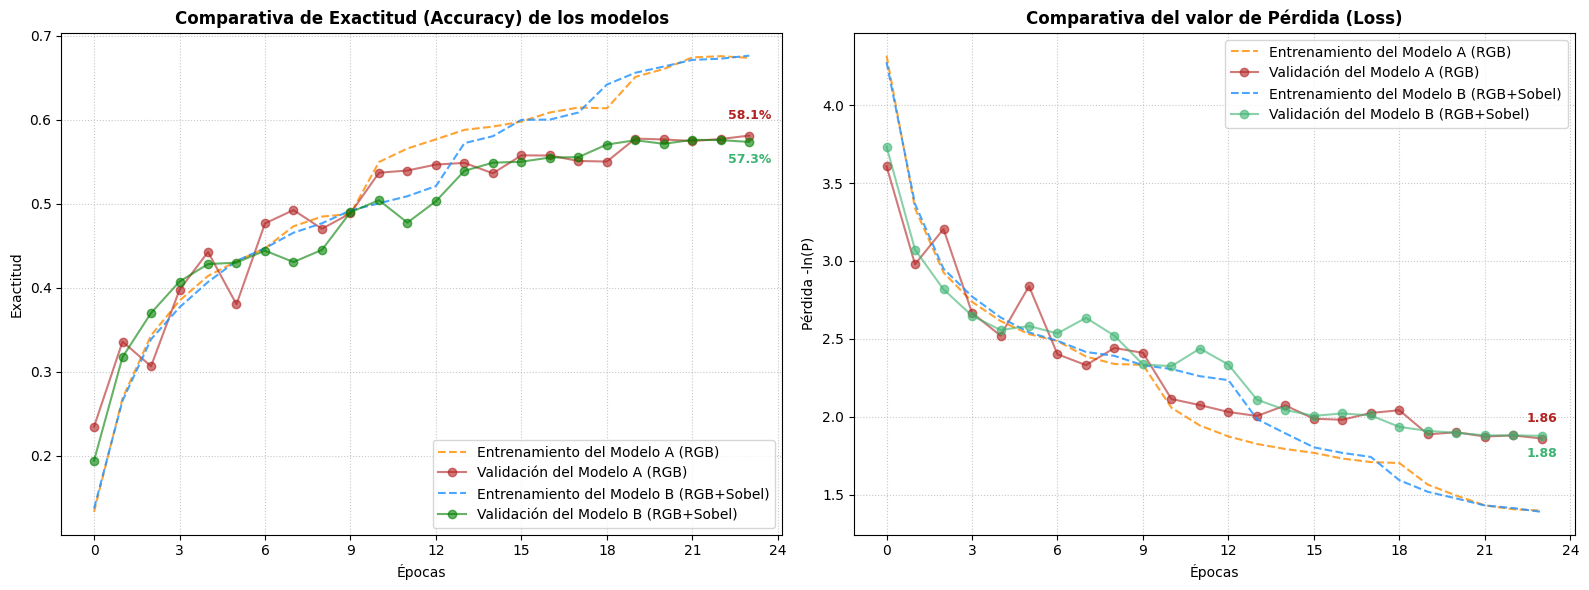

Generando predicciones para el Modelo A...
Generando predicciones para el Modelo B...


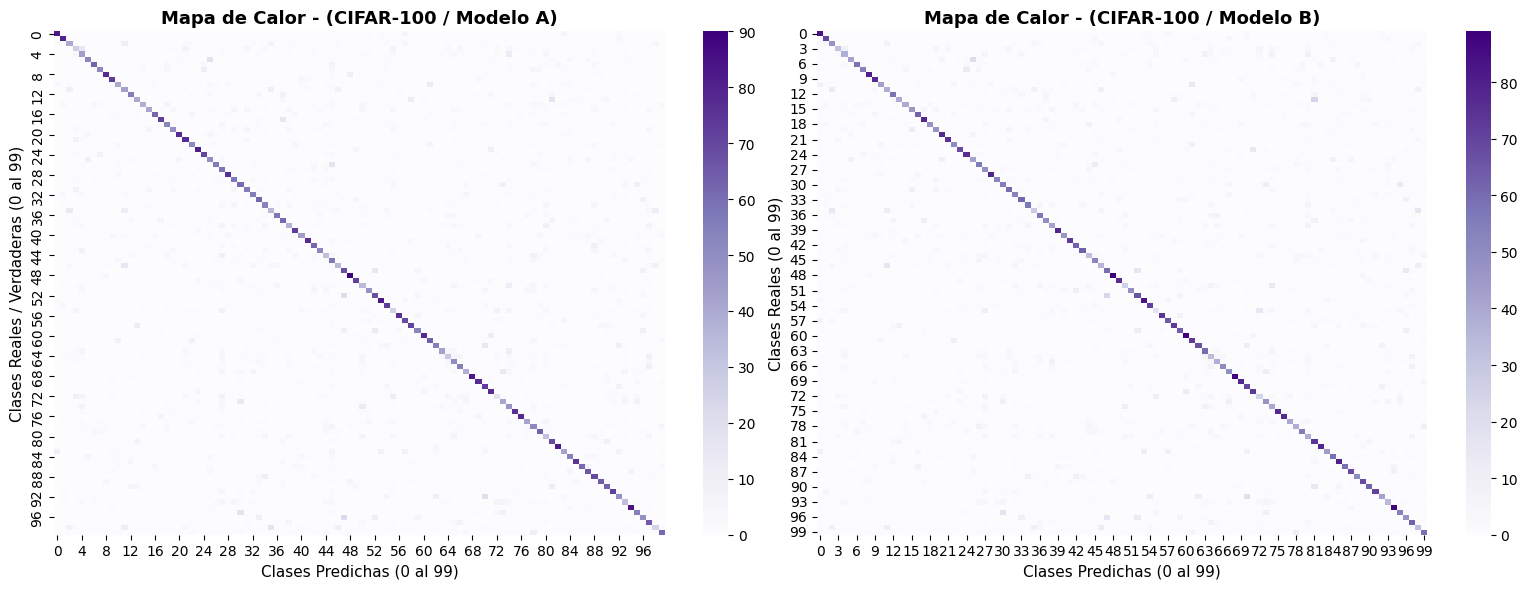

=== REPORTE DE CLASIFICACIÓN - MODELO A (Muestra de Clases) ===
            precision  recall  f1-score  support
road         0.872340    0.82  0.845361    100.0
wardrobe     0.825243    0.85  0.837438    100.0
sunflower    0.828283    0.82  0.824121    100.0
chair        0.865169    0.77  0.814815    100.0
motorcycle   0.743802    0.90  0.814480    100.0
apple        0.783019    0.83  0.805825    100.0
orange       0.783019    0.83  0.805825    100.0
skyscraper   0.829787    0.78  0.804124    100.0
lawn_mower   0.836957    0.77  0.802083    100.0
skunk        0.835165    0.76  0.795812    100.0



=== REPORTE DE CLASIFICACIÓN - MODELO B (Muestra de Clases) ===
            precision  recall  f1-score  support
road         0.862745    0.88  0.871287    100.0
motorcycle   0.809091    0.89  0.847619    100.0
cup          0.857143    0.78  0.816754    100.0
orange       0.768519    0.83  0.798077    100.0
skunk        0.827957    0.77  0.797927    100.0
palm_tree    0.831461    0.74  0.783

In [ ]:

plt.figure(figsize=(16, 6))     # Figure size to plot

# Get ranges from both models, according to the current executed epochs
epochs_a = range(len(history_a.history['accuracy']))
epochs_b = range(len(history_b.history['accuracy']))
final_epoch_a = len(epochs_a) - 1
final_epoch_b = len(epochs_b) - 1

#-------------------------------TRAIN Metrics--------------------------------------------#
# Chart 1: Accuracy for both, training and validation sets (from training macrosets)
plt.subplot(1, 2, 1)
# Double dashed "--" lines represent the training, meanwhile, continue line "-" represent validation per epoch
plt.plot(epochs_a, history_a.history['accuracy'], label='Entrenamiento del Modelo A (RGB)', linestyle='--',color='darkorange', alpha=0.8)
plt.plot(epochs_a, history_a.history['val_accuracy'], label='Validación del Modelo A (RGB)', linestyle='-', marker='o',color='firebrick', linewidth=1.5, alpha=0.6)
plt.plot(epochs_b, history_b.history['accuracy'], label='Entrenamiento del Modelo B (RGB+Sobel)', linestyle='--',color='dodgerblue', alpha=0.8)
plt.plot(epochs_b, history_b.history['val_accuracy'], label='Validación del Modelo B (RGB+Sobel)', linestyle='-', marker='o',color='green', linewidth=1.5, alpha=0.6)

# Tags with last validation accuracy in percentage resolution
val_acc_a_pct = history_a.history['val_accuracy'][-1] * 100
val_acc_b_pct = history_b.history['val_accuracy'][-1] * 100
# Show tags in percentage format, using only 1 decimal point.
plt.annotate(f'{val_acc_a_pct:.1f}%', 
             (final_epoch_a, history_a.history['val_accuracy'][-1]),
             textcoords="offset points", xytext=(0, 12), ha='center', fontsize=9, fontweight='bold', color='firebrick')
plt.annotate(f'{val_acc_b_pct:.1f}%', 
             (final_epoch_b, history_b.history['val_accuracy'][-1]),
             textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, fontweight='bold', color='mediumseagreen')
plt.title('Comparativa de Exactitud (Accuracy) de los modelos', fontsize=12, fontweight='bold')
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Exactitud', fontsize=10)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True)) # Force integer numbers in X-Axis
plt.legend(loc='lower right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.7)

# CHART 2: Loss value for both, training and validation sets (from training macrosets)
plt.subplot(1, 2, 2)
plt.plot(epochs_a, history_a.history['loss'], label='Entrenamiento del Modelo A (RGB)', linestyle='--',color='darkorange', alpha=0.8)
plt.plot(epochs_a, history_a.history['val_loss'], label='Validación del Modelo A (RGB)', linestyle='-', marker='o',color='firebrick', linewidth=1.5, alpha=0.6)
plt.plot(epochs_b, history_b.history['loss'], label='Entrenamiento del Modelo B (RGB+Sobel)', linestyle='--',color='dodgerblue', alpha=0.8)
plt.plot(epochs_b, history_b.history['val_loss'], label='Validación del Modelo B (RGB+Sobel)', linestyle='-', marker='o',color='mediumseagreen', linewidth=1.5, alpha=0.6)

# Tags with last validation loss value
val_loss_a = history_a.history['val_loss'][-1]
val_loss_b = history_b.history['val_loss'][-1]
# Show tags in float format, using only 1 decimal point.
plt.annotate(f'{val_loss_a:.2f}', 
             (final_epoch_a, history_a.history['val_loss'][-1]),
             textcoords="offset points", xytext=(0, 12), ha='center', fontsize=9, fontweight='bold', color='firebrick')
plt.annotate(f'{val_loss_b:.2f}', 
             (final_epoch_b, history_b.history['val_loss'][-1]),
             textcoords="offset points", xytext=(0, -15), ha='center', fontsize=9, fontweight='bold', color='mediumseagreen')

plt.title('Comparativa del valor de Pérdida (Loss)', fontsize=12, fontweight='bold')
plt.xlabel('Épocas', fontsize=10)
plt.ylabel('Pérdida -ln(P)', fontsize=10)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True)) # Forzar exclusivamente números enteros en el eje X
plt.legend(loc='upper right', frameon=True)
plt.grid(True, linestyle=':', alpha=0.7)

# Adjust charts and show
plt.tight_layout()
plt.show()
#-------------------------------TRAIN Metrics--------------------------------------------#


#-------------------------------TEST Metrics--------------------------------------------#
# Get discrete predictions of Model A over Test set
print("Generando predicciones para el Modelo A...")
y_pred_a = np.argmax(modelo_a.predict(x_test, verbose=0), axis=1)
# Calculate confussion Matrix (100x100)
cm_a = confusion_matrix(y_test, y_pred_a)

print("Generando predicciones para el Modelo B...")
y_pred_b = np.argmax(modelo_b.predict(x_test_b, verbose=0), axis=1)
# Calculate confussion Matrix (100x100)
cm_b = confusion_matrix(y_test, y_pred_b)
# Condigure plot size
plt.figure(figsize=(16, 6))

# ==========================================
# Subplot 1: Model A (RGB)
# ==========================================
plt.subplot(1, 2, 1)
sns.heatmap(
    cm_a, 
    cmap='Purples',       # Color pallete (warm tones)
    cbar=True,          # Show side bar with intensities 
)
plt.title('Mapa de Calor - (CIFAR-100 / Modelo A)', fontsize=13, fontweight='bold')
plt.xlabel('Clases Predichas (0 al 99)', fontsize=11)
plt.ylabel('Clases Reales / Verdaderas (0 al 99)', fontsize=11)
plt.tight_layout()
# ==========================================
# Subplot 2: Model B (RGB + Sobel)
# ==========================================
plt.subplot(1, 2, 2)
sns.heatmap(
    cm_b, 
    cmap='Purples',       # Color pallete (cold tones)
    cbar=True,          # Show side bar with intensities 
)
plt.title('Mapa de Calor - (CIFAR-100 / Modelo B)', fontsize=13, fontweight='bold')
plt.xlabel('Clases Predichas (0 al 99)', fontsize=11)
plt.ylabel('Clases Reales (0 al 99)', fontsize=11)

# Adjust design to avoid overlaping and show
plt.tight_layout()
plt.show()

# Oficial list for CIFAR-100 classes
names_cifar100 = [
    'apple', 'aquarium_fish', 'baby', 'bear', 'beaver', 'bed', 'bee', 'beetle', 
    'bicycle', 'bottle', 'bowl', 'boy', 'bridge', 'bus', 'butterfly', 'camel', 
    'can', 'castle', 'caterpillar', 'cattle', 'chair', 'chimpanzee', 'clock', 
    'cloud', 'cockroach', 'couch', 'crab', 'crocodile', 'cup', 'dinosaur', 
    'dolphin', 'elephant', 'flatfish', 'forest', 'fox', 'girl', 'hamster', 
    'house', 'kangaroo', 'keyboard', 'lamp', 'lawn_mower', 'leopard', 'lion', 
    'lizard', 'lobster', 'man', 'maple_tree', 'motorcycle', 'mountain', 'mouse', 
    'mushroom', 'oak_tree', 'orange', 'orchid', 'otter', 'palm_tree', 'pear', 
    'pickup_truck', 'pine_tree', 'plain', 'plate', 'poppy', 'porcupine', 
    'possum', 'rabbit', 'raccoon', 'ray', 'road', 'rocket', 'rose', 
    'sea', 'seal', 'shark', 'shrew', 'skunk', 'skyscraper', 'snail', 'snake', 
    'spider', 'squirrel', 'streetcar', 'sunflower', 'sweet_pepper', 'table', 
    'tank', 'telephone', 'television', 'tiger', 'tractor', 'train', 'trout', 
    'tulip', 'turtle', 'wardrobe', 'whale', 'willow_tree', 'wolf', 'woman', 'worm'
]


import pandas as pd
from sklearn.metrics import classification_report

# Get report as dictionary
report_dict_a = classification_report(
    y_test, 
    y_pred_a, 
    target_names=names_cifar100, 
    zero_division=0, 
    output_dict=True
)

# Convert to Dataframe and split in global averages
df_report_a = pd.DataFrame(report_dict_a).transpose()
summary_a = df_report_a.loc[['accuracy', 'macro avg', 'weighted avg']]
df_classes_a = df_report_a.drop(index=['accuracy', 'macro avg', 'weighted avg'])
# Order by F1-Score
df_sorted_a = df_classes_a.sort_values(by='f1-score', ascending=False)
# Unify rows at the end of the table
df_final_a = pd.concat([df_sorted_a, summary_a])

print("=== REPORTE DE CLASIFICACIÓN - MODELO A (Muestra de Clases TOP 10) ===")
print(df_final_a.head(10).to_string())

print("\n\n")
report_dict_b = classification_report(
    y_test, 
    y_pred_b, 
    target_names=names_cifar100, 
    zero_division=0, 
    output_dict=True
)
# Convert to Dataframe and split in global averages
df_report_b = pd.DataFrame(report_dict_b).transpose()
summary_b = df_report_b.loc[['accuracy', 'macro avg', 'weighted avg']]
df_classes_b = df_report_b.drop(index=['accuracy', 'macro avg', 'weighted avg'])
# Order by F1-Score
df_sorted_b = df_classes_b.sort_values(by='f1-score', ascending=False)
# Unify rows at the end of the table
df_final_b = pd.concat([df_sorted_b, summary_b])
print("=== REPORTE DE CLASIFICACIÓN - MODELO B (Muestra de Clases TOP 10) ===")
print(df_final_b.head(10).to_string())
#-------------------------------TEST Metrics--------------------------------------------#




# Reflexión del perfil 5 - Detección temprana de diabetes Mellitus tipo 2

## El cambio dimensional de los datos
Durante la práctica, se experimentó con redes neuronales convolucionales que procesan la información en formato matricial `2D` para después vectorizar los datos en la capa de aplanamiento (__flatten__) y transformar los datos en formato lineal `1D`. El procesar estos datos originales como una cadena de pixeles unidimensional hubiera requerido un diseño mucho más cuantioso en cuestión de parámetros, lo cual sería ineficiente y costoso. El cambio de una convolución bidimensional a una unidimensional (flatten) se reduce a la dirección en la que el filtro analiza la información. Mientras que el filtro 2D se mueve en un espacio de dos direcciones , el filtro 1D se desliza en una sola dirección a lo largo del tiempo o de una lista ordenada, detectando cómo un evento clínico está relacionado con el anterior.

## Detección de vecindades
Durante la búsqueda del marco teórico encontré otros estudios se han utilizado datos ómicos en formato matricial para poder procesar relaciones complejas entre biomarcadores que, inicialmente parecían no tener relación directa en una línea temporal, pero que a través de una red neuronal convolucional, la relación era más evidente. Trasladando esto a un modelo de detección temprana de diabetes, la elección de un "rasgo diseñado" podría ser crear una variable clínica derivada de los datos del paciente, a través de analizar sus patrones en formato matricial y derivada de otras variables clínicas que podrían no tener una progresión temporal "evidente".

Por ejemplo, se podría calcular una razón de cambio (aceleración) en los niveles de glucosa a través del tiempo, ya sea en registros de pacientes con diferentes edades, o bien, generar una puntuación de riesgo metabólico al analizar las vecindades de las comorbilidades registradas en pacientes a diferentes edades. A pesar de que no se cuenta con un registro nacional de diabetes con biomarcadores, se puede usar la información estadística de los repositorios de egresos hospitalarios para construir perfiles sintéticos con información "oculta" a través del procesamiento en una dimensión distinta a la tabular. 